# Classificação e Pipelines com scikit-learn

**Disciplina:** Ferramentas para Data Science — UFSJ  
**Atividade:** Classificação utilizando o dataset Wine, Regressão Logística e KNN.

O objetivo é comparar dois pipelines, evitando vazamento de dados ao separar treino e teste e aplicar padronização dentro da validação cruzada.

## 1. Carregamento e particionamento dos dados

O conjunto Wine possui 13 atributos físico-químicos e 3 classes. A divisão reserva 75% para treino e 25% para teste. Utilizamos `stratify=y` para preservar aproximadamente a proporção das classes e `random_state=42` para reproduzir a separação.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print(f"Amostras: {len(X)} | Atributos: {X.shape[1]} | Classes: {y.nunique()}")
print("Distribuição das classes:")
print(y.value_counts().sort_index())
display(X.head())

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras")

Amostras: 178 | Atributos: 13 | Classes: 3
Distribuição das classes:
target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Treino: 133 amostras | Teste: 45 amostras


## 2. Construção dos pipelines

Em ambos os modelos, a padronização é aprendida somente a partir dos dados de treino de cada ajuste. O KNN usa cinco vizinhos e a regressão logística tem até 1000 iterações.

In [2]:
pipeline_a = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(max_iter=1000, random_state=42)),
])

pipeline_b = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", KNeighborsClassifier(n_neighbors=5)),
])

modelos = {
    "Regressão Logística": pipeline_a,
    "KNN (k=5)": pipeline_b,
}
print("Pipelines criados:", ", ".join(modelos))

Pipelines criados: Regressão Logística, KNN (k=5)


## 3. Validação cruzada no conjunto de treino

Usamos `cross_val_score` com `cv=5`. Para classificadores com classes discretas, essa configuração usa 5 partições estratificadas. A métrica é **acurácia**, medida somente nos dados de validação de cada partição.

In [3]:
resultados_cv = {}
for nome, modelo in modelos.items():
    pontuacoes = cross_val_score(modelo, X_treino, y_treino, cv=5, scoring="accuracy")
    resultados_cv[nome] = pontuacoes

resumo_cv = pd.DataFrame({
    nome: {
        "Média": pontuacoes.mean(),
        "Desvio padrão": pontuacoes.std(),
        "Mínimo": pontuacoes.min(),
        "Máximo": pontuacoes.max(),
    }
    for nome, pontuacoes in resultados_cv.items()
}).T
print("Acurácia por partição (5 folds):")
for nome, pontuacoes in resultados_cv.items():
    print(f"{nome}: {np.round(pontuacoes, 4)}")
display(resumo_cv.round(4))

Acurácia por partição (5 folds):
Regressão Logística: [1.     1.     0.963  1.     0.9615]
KNN (k=5): [1.     0.8889 0.963  0.9615 0.9615]


,Média,Desvio padrão,Mínimo,Máximo
Regressão Logística,0.9849,0.0185,0.9615,1.0
KNN (k=5),0.9550,0.0362,0.8889,1.0


## 4. Avaliação final no conjunto de teste

Treinamos cada pipeline com **todo o conjunto de treino** e geramos previsões para o teste separado no início. Escolhemos o pipeline com maior **acurácia média na validação cruzada**, para não usar o conjunto de teste como critério de seleção do modelo.


===== Regressão Logística =====
Acurácia no teste: 1.0000
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


===== KNN (k=5) =====
Acurácia no teste: 0.9333
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45

Melhor pipeline pela média da validação cruzada: Regressão Logística


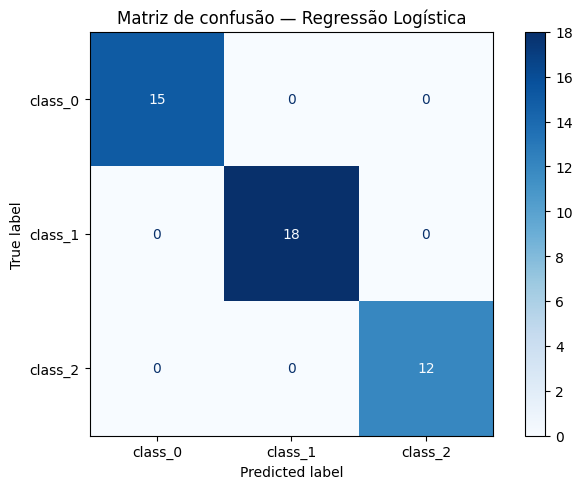

In [4]:
resultados_teste = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)
    resultados_teste[nome] = {
        "modelo": modelo,
        "previsoes": previsoes,
        "acuracia": accuracy_score(y_teste, previsoes),
    }
    print(f"\n===== {nome} =====")
    print(f"Acurácia no teste: {resultados_teste[nome]['acuracia']:.4f}")
    print(classification_report(
        y_teste, previsoes,
        labels=np.arange(len(wine.target_names)),
        target_names=wine.target_names,
        zero_division=0,
    ))

melhor_nome = max(modelos, key=lambda nome: resultados_cv[nome].mean())
melhor_modelo = resultados_teste[melhor_nome]["modelo"]
print(f"Melhor pipeline pela média da validação cruzada: {melhor_nome}")

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_estimator(
    melhor_modelo, X_teste, y_teste,
    display_labels=wine.target_names,
    cmap="Blues", values_format="d", ax=ax,
)
ax.set_title(f"Matriz de confusão — {melhor_nome}")
plt.tight_layout()
plt.show()

## 5. Análise crítica e fundamentação

### 5.1 Escalonamento e distâncias

O **KNeighborsClassifier** classifica amostras por proximidade, normalmente utilizando distância euclidiana. No Wine, atributos como `proline` e `magnesium` possuem escalas numéricas muito diferentes de atributos como `hue` ou `nonflavanoid_phenols`. Sem padronização, variáveis com valores absolutos maiores podem dominar as distâncias e reduzir a influência das demais. O `StandardScaler` centraliza cada atributo na média e ajusta seu desvio padrão para aproximadamente 1, permitindo que as características contribuam de maneira mais equilibrada.

### 5.2 Prevenção de vazamento de dados

Ao colocar `StandardScaler` **dentro** de `Pipeline`, o `cross_val_score` ajusta o escalonador apenas com a parcela de treino de cada fold e aplica a transformação à parcela de validação sem recalcular média ou desvio padrão com ela. Isso impede que informações estatísticas da validação influenciem o treinamento. Após a validação cruzada, cada pipeline é ajustado sobre o conjunto de treino completo; o conjunto de teste continua separado até a avaliação final.

### Conclusão

A comparação usa a mesma separação de dados e o mesmo processo de padronização para ambos os modelos. As pontuações da validação cruzada orientam a escolha do melhor pipeline, enquanto os relatórios no conjunto de teste permitem avaliar o desempenho final por classe. Variações pequenas entre os modelos devem ser interpretadas considerando o tamanho relativamente pequeno do dataset Wine.